# NYC Yellow Taxi Demand: Trends and Forecasting

This notebook aggregates pickup timestamps into **daily trip counts** and explores demand trends. It compares a weekly seasonal-naive baseline with a Random Forest model using lagged demand and calendar features, then forecasts the 14 days following the observed data.

The source file contains pickup and drop-off timestamps only, so this is a forecast of **trip volume**, not trip duration, fares, or locations. It covers only January and February 2023; results are exploratory and cannot establish annual or long-term seasonality.

## Setup

Install the project dependencies from the repository root before running the notebook:

```bash
python -m pip install -r requirements.txt
```

The forecasting and plotting cells use pandas, NumPy, Matplotlib, and scikit-learn.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42
HORIZON_DAYS = 14
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)

## Load and validate the trips

The path check supports execution from either the repository root or the `notebooks/` directory. Invalid pickup timestamps are excluded explicitly; missing calendar dates, if any, are represented as zero-trip days.

In [9]:
data_candidates = [
    Path.cwd() / "data" / "taxi_trips.parquet",
    Path.cwd().parent / "data" / "taxi_trips.parquet",
]
DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    searched = ", ".join(str(path) for path in data_candidates)
    raise FileNotFoundError(f"Could not find data/taxi_trips.parquet. Searched: {searched}")

required_columns = ["tpep_pickup_datetime", "tpep_dropoff_datetime"]
trips = pd.read_parquet(DATA_PATH, columns=required_columns)
trips["tpep_pickup_datetime"] = pd.to_datetime(
    trips["tpep_pickup_datetime"], errors="coerce"
)
trips["tpep_dropoff_datetime"] = pd.to_datetime(
    trips["tpep_dropoff_datetime"], errors="coerce"
)

invalid_pickups = int(trips["tpep_pickup_datetime"].isna().sum())
valid_pickups = trips.dropna(subset=["tpep_pickup_datetime"])
if valid_pickups.empty:
    raise ValueError("No valid pickup timestamps are available for forecasting.")

daily_demand = (
    valid_pickups.assign(date=valid_pickups["tpep_pickup_datetime"].dt.normalize())
    .groupby("date")
    .size()
    .sort_index()
    .asfreq("D", fill_value=0)
    .astype("int64")
    .rename("trip_count")
)

print(f"Source: {DATA_PATH}")
print(f"Rows read: {len(trips):,}")
print(f"Invalid pickup timestamps excluded: {invalid_pickups:,}")
print(f"Daily observations: {len(daily_demand)}")
print(f"Date range: {daily_demand.index.min().date()} to {daily_demand.index.max().date()}")
print(f"Days with no pickups: {(daily_demand == 0).sum()}")
display(daily_demand.describe().to_frame().T)

Source: /home/serhat/Documents/WorkspaceTech/Repos/TaxiRides/data/taxi_trips.parquet
Rows read: 5,980,729
Invalid pickup timestamps excluded: 0
Daily observations: 59
Date range: 2023-01-01 to 2023-02-28
Days with no pickups: 0


,count,mean,std,min,25%,50%,75%,max
trip_count,59.0,101368.288136,12041.895924,65777.0,92063.0,105036.0,111656.5,115492.0


## Daily trend

The seven-day moving average smooths the weekly cycle while preserving the original daily counts for context.

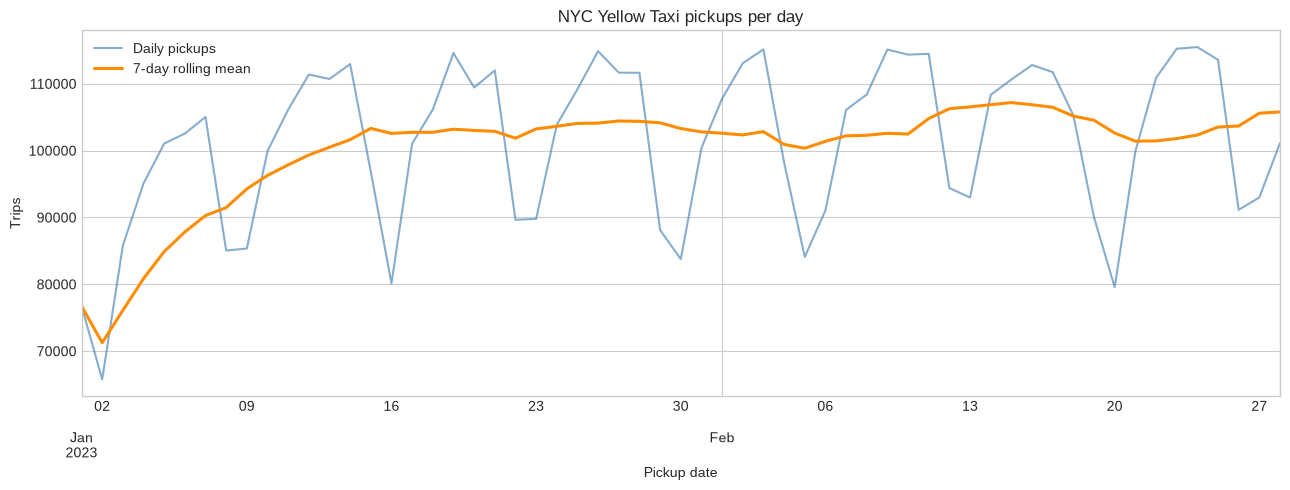

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))
daily_demand.plot(ax=ax, color="steelblue", alpha=0.65, label="Daily pickups")
daily_demand.rolling(7, min_periods=1).mean().plot(
    ax=ax, color="darkorange", linewidth=2.2, label="7-day rolling mean"
)
ax.set(title="NYC Yellow Taxi pickups per day", xlabel="Pickup date", ylabel="Trips")
ax.legend()
plt.tight_layout()
plt.show()

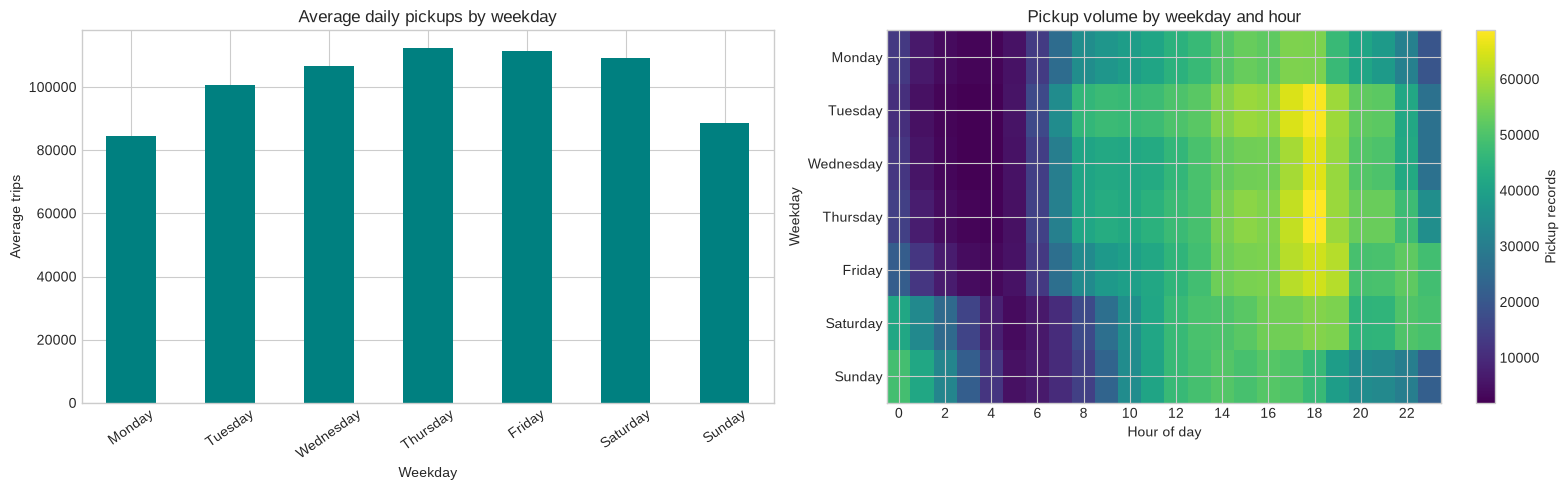

In [11]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pickup_times = valid_pickups["tpep_pickup_datetime"]
pickup_profile = pd.DataFrame(
    {
        "weekday": pd.Categorical(pickup_times.dt.day_name(), categories=weekday_order, ordered=True),
        "hour": pickup_times.dt.hour,
    }
)
weekday_counts = daily_demand.groupby(daily_demand.index.day_name()).mean().reindex(weekday_order)
hourly_by_weekday = pickup_profile.groupby(["weekday", "hour"], observed=False).size().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
weekday_counts.plot(kind="bar", ax=axes[0], color="teal")
axes[0].set(title="Average daily pickups by weekday", xlabel="Weekday", ylabel="Average trips")
axes[0].tick_params(axis="x", rotation=35)
image = axes[1].imshow(hourly_by_weekday.to_numpy(), aspect="auto", cmap="viridis")
axes[1].set(
    title="Pickup volume by weekday and hour",
    xlabel="Hour of day",
    ylabel="Weekday",
    xticks=np.arange(0, 24, 2),
    yticks=np.arange(len(weekday_order)),
    yticklabels=weekday_order,
)
fig.colorbar(image, ax=axes[1], label="Pickup records")
plt.tight_layout()
plt.show()

## Features and chronological holdout

Predictors use only information available before each prediction date: lagged counts (1, 7, and 14 days), trailing means, weekday cycles, weekend status, and a linear time index. The final 14 observations form a chronological holdout. Forecasts are recursive: after each forecast, its value is used to form later lag features.

In [12]:
def features_from_history(history, target_date, origin_date):
    """Build one row of features using values strictly before target_date."""
    values = np.asarray(history, dtype=float)
    if len(values) < 14:
        raise ValueError("At least 14 historical daily counts are required.")
    weekday = target_date.dayofweek
    return {
        "lag_1": values[-1],
        "lag_7": values[-7],
        "lag_14": values[-14],
        "mean_7": values[-7:].mean(),
        "mean_14": values[-14:].mean(),
        "weekday_sin": np.sin(2 * np.pi * weekday / 7),
        "weekday_cos": np.cos(2 * np.pi * weekday / 7),
        "is_weekend": int(weekday >= 5),
        "day_index": (target_date - origin_date).days,
    }


def make_supervised(series):
    """Create training rows; each row's lag features precede its target."""
    records = []
    origin_date = series.index[0]
    for position in range(14, len(series)):
        target_date = series.index[position]
        history = series.iloc[:position].to_numpy()
        record = features_from_history(history, target_date, origin_date)
        record["target"] = float(series.iloc[position])
        records.append(record)
    supervised = pd.DataFrame(records)
    return supervised.drop(columns="target"), supervised["target"]


def recursive_model_forecast(model, initial_history, target_dates, origin_date):
    history = list(np.asarray(initial_history, dtype=float))
    predictions = []
    for target_date in target_dates:
        row = pd.DataFrame([features_from_history(history, target_date, origin_date)])
        prediction = max(0.0, float(model.predict(row)[0]))
        predictions.append(prediction)
        history.append(prediction)
    return np.asarray(predictions)


def recursive_seasonal_naive(initial_history, target_dates):
    """Repeat the count from seven days earlier, recursively."""
    history = list(np.asarray(initial_history, dtype=float))
    predictions = []
    for _ in target_dates:
        prediction = max(0.0, history[-7])
        predictions.append(prediction)
        history.append(prediction)
    return np.asarray(predictions)


def forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual) + np.abs(predicted)
    smape_terms = np.divide(
        2 * np.abs(actual - predicted), denominator,
        out=np.zeros_like(denominator), where=denominator != 0,
    )
    return {
        "MAE (trips)": np.mean(np.abs(actual - predicted)),
        "RMSE (trips)": np.sqrt(np.mean((actual - predicted) ** 2)),
        "sMAPE (%)": 100 * np.mean(smape_terms),
    }


if len(daily_demand) <= HORIZON_DAYS + 14:
    raise ValueError("Need more than 28 daily observations for a 14-day holdout and 14-day lags.")

train_series = daily_demand.iloc[:-HORIZON_DAYS]
test_series = daily_demand.iloc[-HORIZON_DAYS:]
X_train, y_train = make_supervised(train_series)
if X_train.empty:
    raise ValueError("Not enough training observations after creating lag features.")

model = RandomForestRegressor(
    n_estimators=400,
    max_depth=3,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
model.fit(X_train, y_train)
rf_test = recursive_model_forecast(
    model, train_series.to_numpy(), test_series.index, daily_demand.index[0]
)
naive_test = recursive_seasonal_naive(train_series.to_numpy(), test_series.index)

metrics = pd.DataFrame(
    {
        "Weekly seasonal naive": forecast_metrics(test_series, naive_test),
        "Random Forest": forecast_metrics(test_series, rf_test),
    }
).T
display(metrics.round(2))
print(f"Training rows after lags: {len(X_train)}; holdout days: {len(test_series)}")

,MAE (trips),RMSE (trips),sMAPE (%)
Weekly seasonal naive,4122.43,5626.06,4.12
Random Forest,3289.64,4027.13,3.30


Training rows after lags: 31; holdout days: 14


,Actual,Weekly seasonal naive,Random Forest
date,,,
2023-02-15,110638,108397,108378
2023-02-16,112816,115122,112599
2023-02-17,111745,114361,112508
2023-02-18,105272,114484,108917
2023-02-19,90018,94403,91658
2023-02-20,79583,92981,89103
2023-02-21,99877,108344,105610
2023-02-22,110874,108397,107974
2023-02-23,115242,115122,112597


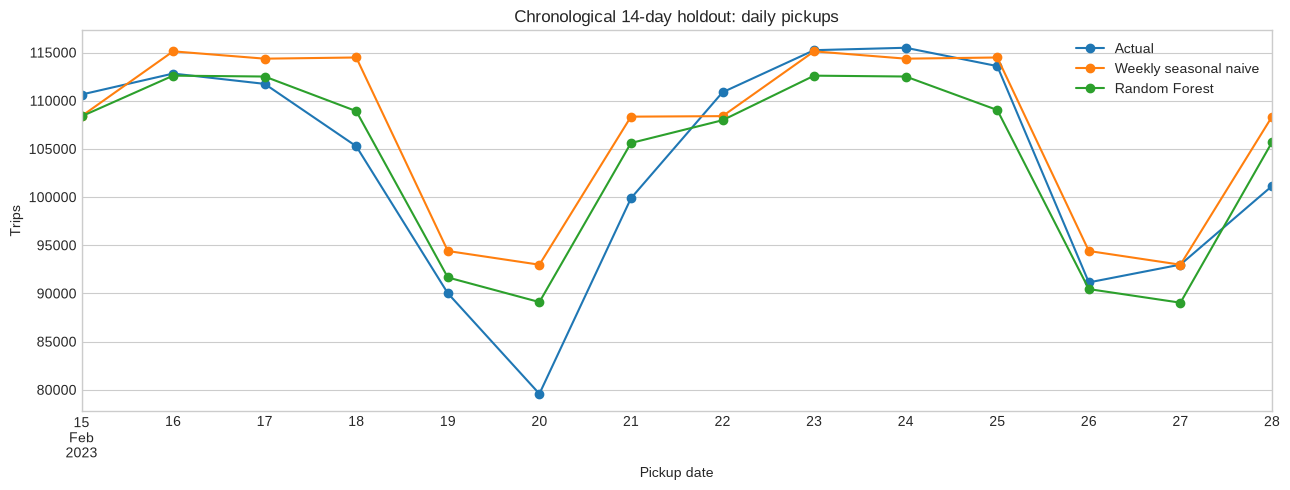

In [13]:
holdout = pd.DataFrame(
    {
        "Actual": test_series.to_numpy(),
        "Weekly seasonal naive": naive_test,
        "Random Forest": rf_test,
    },
    index=test_series.index,
)
display(holdout.round(0).astype(int))
ax = holdout.plot(figsize=(13, 5), marker="o")
ax.set(title="Chronological 14-day holdout: daily pickups", xlabel="Pickup date", ylabel="Trips")
plt.tight_layout()
plt.show()

## Forecast the next 14 days

After inspecting holdout performance, refit the same model on all available historical days. Future values are generated recursively. Model outputs are estimates, not prediction intervals; the short sample and absence of external variables limit their reliability.

/tmp/ipykernel_80915/3817070486.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=daily_demand.index[-1] + pd.Timedelta(days=1),


,forecast_trips
2023-03-01,108751
2023-03-02,112626
2023-03-03,112520
2023-03-04,108915
2023-03-05,89011
2023-03-06,85547
2023-03-07,102732
2023-03-08,109334
2023-03-09,113175
2023-03-10,112970


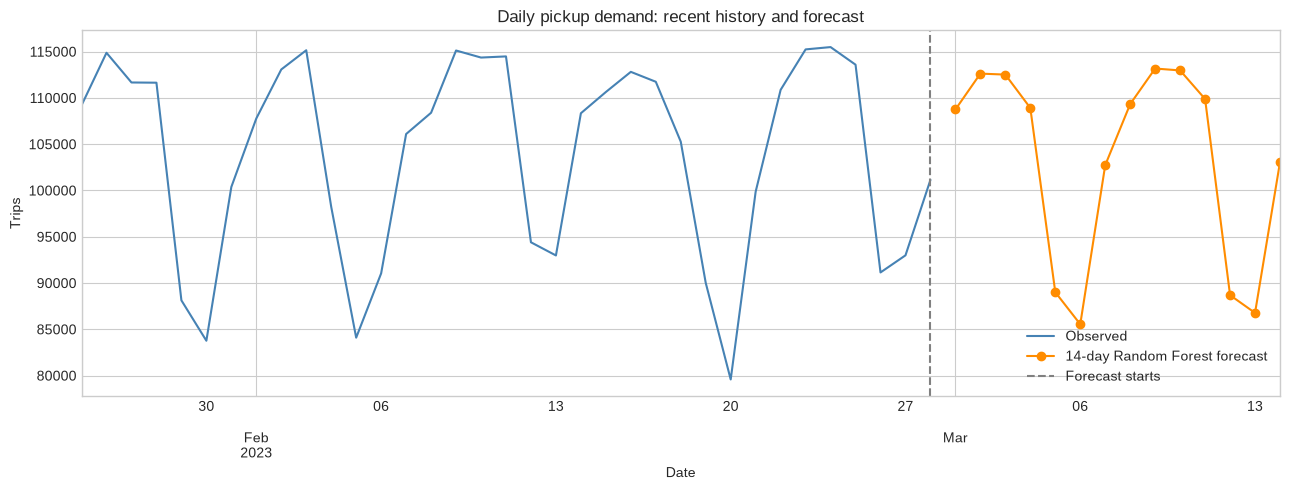

In [14]:
X_all, y_all = make_supervised(daily_demand)
final_model = RandomForestRegressor(
    n_estimators=400,
    max_depth=3,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_model.fit(X_all, y_all)
future_dates = pd.date_range(
    start=daily_demand.index[-1] + pd.Timedelta(days=1),
    periods=HORIZON_DAYS,
    freq="D",
)
future_values = recursive_model_forecast(
    final_model, daily_demand.to_numpy(), future_dates, daily_demand.index[0]
)
future_forecast = pd.Series(
    np.rint(future_values).astype("int64"), index=future_dates, name="forecast_trips"
)
display(future_forecast.to_frame())

fig, ax = plt.subplots(figsize=(13, 5))
daily_demand.tail(35).plot(ax=ax, label="Observed", color="steelblue")
future_forecast.plot(ax=ax, label="14-day Random Forest forecast", color="darkorange", marker="o")
ax.axvline(daily_demand.index[-1], color="gray", linestyle="--", label="Forecast starts")
ax.set(title="Daily pickup demand: recent history and forecast", xlabel="Date", ylabel="Trips")
ax.legend()
plt.tight_layout()
plt.show()

## Interpretation notes

- Compare holdout errors with the weekly seasonal-naive baseline; a more complex model is useful only if it improves on that reference.
- The holdout is one 14-day period and the training set is small after lag features are created, so the scores are not a guarantee of future performance.
- The forecast extrapolates only patterns present in two months of pickup counts. Holidays, weather, service changes, and longer seasonal cycles are not modeled.